# Supplementary Figure 1: Package trajectories

Calculate each selected package's reach as a share of indexed full-text microscopy papers in 2010, 2015, 2020, and 2025. The figure uses a separate vertical scale for each package and marks MATLAB and Jupyter notebooks as scale references. See `MANUSCRIPT/02_SUPPLEMENTARY_INFO.md`, Supplementary Figures, Figure S1 caption, and `MANUSCRIPT/01_MAIN.md`, Methods, Denominators.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import sfig1_trajectories as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

The registry query combines each package's aliases with the shared indexed-full-text microscopy context. The yearly query adds the publication year. MATLAB and Jupyter notebooks remain in the per-package display and stay outside field aggregates.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'cellpose', 'matlab']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."
12,matlab,MATLAB,"""MATLAB"" AND ((microscopy OR microscope) AND H..."


In [3]:
inspect_processed('literature_yearly.csv')
inspect_processed('corpus_yearly.csv')
inspect_processed('tools.csv')

literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


corpus_yearly.csv: shape=(16, 2)


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986


tools.csv: shape=(30, 7)


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io
5,icy,Icy,general-platform,False,True,core,https://icy.bioimageanalysis.org
6,ilastik,ilastik,general-platform,False,True,core,https://www.ilastik.org
7,knime,KNIME,general-platform,False,True,core,https://www.knime.com
8,cellpose,Cellpose,dl-model,True,True,core,https://www.cellpose.org
9,stardist,StarDist,dl-model,True,True,core,https://github.com/stardist/stardist


## Reach derivation

`style.reach([tool_id])` divides a package's yearly Europe PMC matches by the yearly microscopy denominator. We display four years for six packages. The manuscript figure includes all registry packages, each with its own vertical scale.


In [4]:
trajectory_tools = ['imagej', 'qupath', 'cellprofiler', 'napari', 'cellpose', 'stardist']
years = [2010, 2015, 2020, 2025]
rows = []
for tool_id in trajectory_tools:
    reach = fs.reach([tool_id])
    for year in years:
        rows.append({'tool_id': tool_id, 'year': year, 'reach_percent': reach.loc[year]})
trajectory = pd.DataFrame(rows)
print(f'Selected trajectory table shape: {trajectory.shape}')
display(trajectory.pivot(index='tool_id', columns='year', values='reach_percent').round(2))

latest = fs.europepmc_yearly().query('year == 2025').set_index('tool_id')['count']
registry_names = registry_table.set_index('tool_id')['name']
display(pd.DataFrame([{'tool_id': tool, 'name': registry_names.loc[tool], 'papers_2025': int(latest.loc[tool]),
                       'reach_2025_percent': fs.reach([tool]).loc[2025]} for tool in trajectory_tools]))

Selected trajectory table shape: (24, 3)


year,2010,2015,2020,2025
tool_id,,,,
cellpose,0.00,0.00,0.01,0.44
cellprofiler,0.10,0.28,0.40,0.58
imagej,10.45,16.89,21.92,27.77
napari,0.00,0.00,0.00,0.16
qupath,0.00,0.00,0.12,0.92
stardist,0.00,0.00,0.01,0.20


,tool_id,name,papers_2025,reach_2025_percent
0,imagej,ImageJ / Fiji,49255,27.771513
1,qupath,QuPath,1625,0.916226
2,cellprofiler,CellProfiler,1032,0.581874
3,napari,napari,278,0.156745
4,cellpose,Cellpose,778,0.438661
5,stardist,StarDist,356,0.200724


## Optional processed-table rebuild from cached Europe PMC responses

Set `REBUILD = True` to reconstruct Europe PMC yearly counts and the microscopy denominator with the pipeline collection functions. A cache-only reader raises on missing responses, so this cell cannot fetch data. It writes comparison CSVs in a temporary folder and leaves `data/processed` unchanged. Repository-star and package-download snapshots remain the saved observations.


In [5]:
REBUILD = False
if REBUILD:
    import json
    from unittest.mock import patch
    from census import _http
    from census.sources import europepmc

    def cached_json(source, url, params=None, **kwargs):
        cache = _http._cache_path(source, url, params)
        if not cache.is_file():
            raise FileNotFoundError(f'Missing cached response: {cache.name}; no request was sent')
        return json.loads(cache.read_text())

    with patch.object(europepmc, 'get_json', cached_json):
        rebuilt_counts = pd.DataFrame(europepmc.collect_yearly(reg))
        rebuilt_corpus = pd.DataFrame(europepmc.corpus_yearly(reg))
    pd.testing.assert_frame_equal(rebuilt_counts.reset_index(drop=True), fs.europepmc_yearly().assign(source='europepmc')[rebuilt_counts.columns].reset_index(drop=True))
    pd.testing.assert_frame_equal(rebuilt_corpus, fs.load('corpus_yearly.csv'))
    with TemporaryDirectory(prefix='cached-processed-rebuild-') as output_dir:
        rebuilt_counts.to_csv(Path(output_dir) / 'literature_europepmc_yearly.csv', index=False)
        rebuilt_corpus.to_csv(Path(output_dir) / 'corpus_yearly.csv', index=False)
        print(f'Cached tables match: counts {rebuilt_counts.shape}, corpus {rebuilt_corpus.shape}')


## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote SFigure1__trajectories.png/.pdf/.svg


wrote SFigure1__trajectories.png/.pdf/.svg


PNG shape: (2338, 2074, 4); mean absolute pixel difference: 0.000000


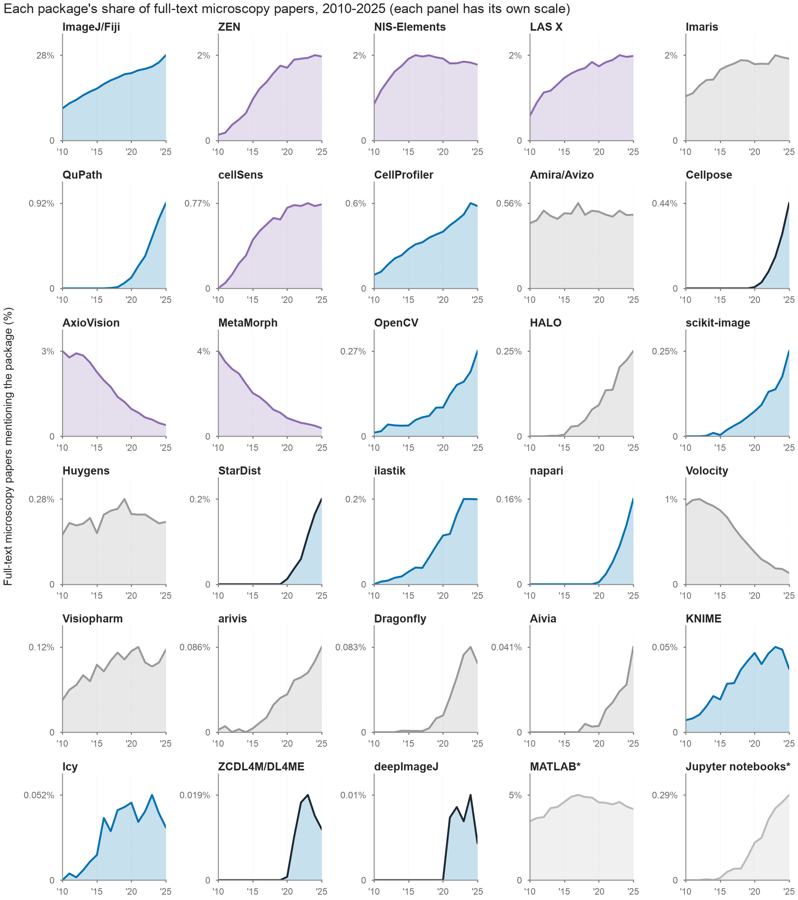

In [6]:
OUTPUT_STEM = 'SFigure1__trajectories'
fig = figure.build_figure()
with TemporaryDirectory(prefix='sfigure1-notebook-') as notebook_dir, TemporaryDirectory(prefix='sfigure1-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')